# Dataset EDA

Run from the project root after `python -m src.prepare_data`.

Every chart here is aggregate only. Sample pages are written to `reports/` (gitignored) rather
than embedded, because the page images belong to their publishers and this notebook is public.

In [1]:
import json
import os
from collections import Counter
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import cv2
import matplotlib.pyplot as plt
import numpy as np

from src.config import load_config
from src.dataset import BubbleDataset, load_records

config = load_config("configs/default.yaml")
splits_dir = config["data"]["splits_dir"]
records = {split: load_records(splits_dir, split) for split in ("train", "val", "test")}
report = json.loads(Path(splits_dir, "report.json").read_text())
{k: report[k] for k in ("raw_pages", "dropped_unreliable_empty", "dropped_cross_split_duplicates", "pages_with_a_duplicate")}

Matplotlib is building the font cache; this may take a moment.


{'raw_pages': 2671,
 'dropped_unreliable_empty': 245,
 'dropped_cross_split_duplicates': 6,
 'pages_with_a_duplicate': 1121}

## Split composition

Whole sources are held out, so no source appears in more than one split.

In [2]:
for split, items in records.items():
    bubbles = sum(len(r["boxes"]) for r in items)
    empty = sum(not r["boxes"] for r in items)
    print(f"{split:5s} pages={len(items):5d} bubbles={bubbles:6d} empty_pages={empty:3d} sources={dict(Counter(r['source'] for r in items))}")

sources = {split: {r["source"] for r in items} for split, items in records.items()}
assert not (sources["train"] & sources["val"] or sources["train"] & sources["test"] or sources["val"] & sources["test"])

groups = {split: {r["duplicate_group"] for r in items} for split, items in records.items()}
assert not (groups["train"] & groups["val"] or groups["train"] & groups["test"] or groups["val"] & groups["test"])
print("OK: no source and no near-duplicate group crosses a split.")

train pages= 1756 bubbles= 10981 empty_pages= 40 sources={'square_640': 1350, 'portrait_844': 404, 'other': 2}
val   pages=  220 bubbles=  1406 empty_pages= 19 sources={'portrait_2150': 220}
test  pages=  444 bubbles=  4361 empty_pages= 14 sources={'portrait_764': 188, 'screens_3840': 92, 'scan_1044': 164}
OK: no source and no near-duplicate group crosses a split.


## Bubbles per page

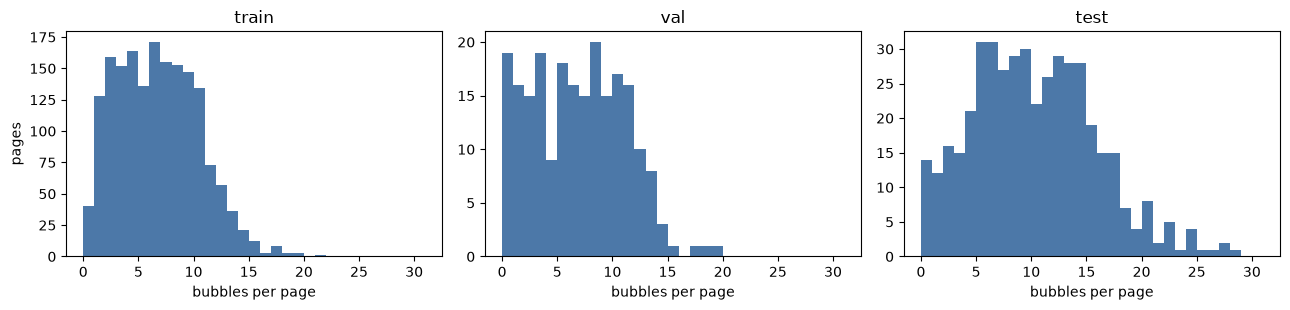

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for ax, (split, items) in zip(axes, records.items()):
    ax.hist([len(r["boxes"]) for r in items], bins=range(0, 32), color="#4c78a8")
    ax.set_title(split)
    ax.set_xlabel("bubbles per page")
axes[0].set_ylabel("pages")
plt.tight_layout()
plt.show()

## Bubble size after preprocessing

Sizes are measured in the 512 x 512 network input, because that is what decides whether a bubble
survives downscaling. This also gives a sensible range for tuning `min_area`.

train area px at 512: p5=    822  median=   4879  p95=  14337
val   area px at 512: p5=    916  median=   3804  p95=   8150
test  area px at 512: p5=    401  median=   2121  p95=   7092


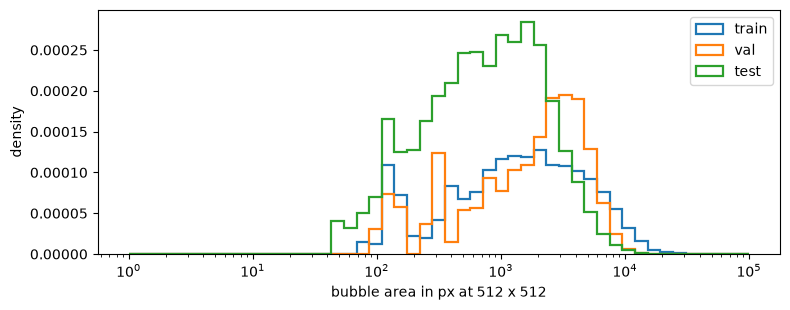

In [4]:
size = config["data"]["image_size"]


def network_areas(items):
    areas = []
    for r in items:
        scale = size / max(r["width"], r["height"])
        areas += [b[2] * b[3] * scale * scale for b in r["boxes"]]
    return np.array(areas)


fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(0, 5, 50)
for split, items in records.items():
    areas = network_areas(items)
    ax.hist(areas, bins=bins, histtype="step", density=True, label=split, linewidth=1.6)
    print(f"{split:5s} area px at {size}: p5={np.percentile(areas, 5):7.0f}  median={np.median(areas):7.0f}  p95={np.percentile(areas, 95):7.0f}")
ax.set_xscale("log")
ax.set_xlabel(f"bubble area in px at {size} x {size}")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.show()

## Per-source view

The 3840 x 2160 sources are two-page screenshots, so their bubbles get very small at 512 px.

In [5]:
by_source = {}
for items in records.values():
    for r in items:
        by_source.setdefault(r["source"], []).append(r)
for source, items in sorted(by_source.items(), key=lambda kv: -len(kv[1])):
    print(f"{source:15s} pages={len(items):5d} median bubble area={np.median(network_areas(items)):7.0f} px  bubbles/page={np.mean([len(r['boxes']) for r in items]):5.1f}")

square_640      pages= 1350 median bubble area=   5645 px  bubbles/page=  6.6
portrait_844    pages=  404 median bubble area=   2209 px  bubbles/page=  5.1
portrait_2150   pages=  220 median bubble area=   3804 px  bubbles/page=  6.4
portrait_764    pages=  188 median bubble area=   3829 px  bubbles/page=  8.2
scan_1044       pages=  164 median bubble area=   1851 px  bubbles/page=  9.8
screens_3840    pages=   92 median bubble area=   1476 px  bubbles/page= 13.2
other           pages=    2 median bubble area=   2578 px  bubbles/page=  5.5


## Class imbalance

This is the reason for adding Dice to BCE: most pixels are background, so a loss averaged over
pixels can look good while the model finds nothing.

train bubble pixels: mean 14.7% of each page (median 13.2%)


val   bubble pixels: mean 14.9% of each page (median 14.4%)


test  bubble pixels: mean 16.0% of each page (median 14.4%)


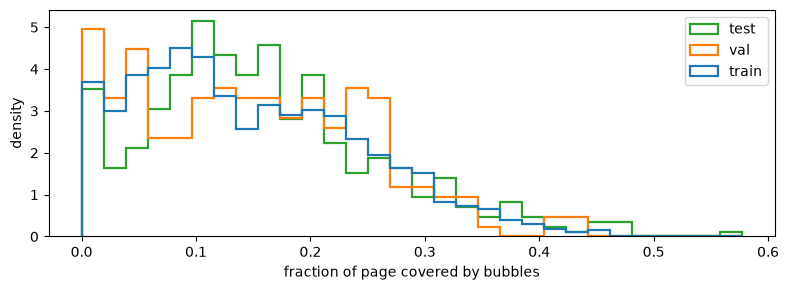

In [6]:
fractions = []
for split, items in records.items():
    values = []
    for r in items:
        mask = cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE)
        values.append((mask > 127).mean())
    fractions.append(values)
    print(f"{split:5s} bubble pixels: mean {np.mean(values):.1%} of each page (median {np.median(values):.1%})")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(fractions, bins=30, density=True, label=list(records), histtype="step", linewidth=1.6)
ax.set_xlabel("fraction of page covered by bubbles")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()
plt.show()

## Sanity check: image and mask stay aligned

Saves five validation samples and five augmented training samples to `reports/sanity_samples.png`.
The green overlay should sit exactly on the bubbles in both rows.

In [7]:
def overlay(item):
    image = ((item["image"][0].numpy() * 0.5 + 0.5) * 255).astype(np.uint8)
    canvas = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    mask = item["mask"][0].numpy() > 0.5
    canvas[mask] = (canvas[mask] * 0.55 + np.array([0, 110, 0])).astype(np.uint8)
    return canvas


rng = np.random.default_rng(config["seed"])
val_set = BubbleDataset(records["val"], size)
train_set = BubbleDataset(records["train"], size, config["augment"])
top = [overlay(val_set[int(i)]) for i in rng.choice(len(val_set), 5, replace=False)]
bottom = [overlay(train_set[int(i)]) for i in rng.choice(len(train_set), 5, replace=False)]
Path("reports").mkdir(exist_ok=True)
cv2.imwrite("reports/sanity_samples.png", np.vstack([np.hstack(top), np.hstack(bottom)]))
print("Saved reports/sanity_samples.png")

Saved reports/sanity_samples.png
